# 02 — product analytics
**Dataset:** Open University Learning Analytics Dataset (OULAD)

Three questions: where do students fall off the funnel, which cohorts retain best, and what is a student worth at each level of engagement.



## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
np.random.seed(42)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi']    = 120

PROC = '../data/processed/'
RAW  = '../data/raw/'

TIER_COLORS = {
    'Inactive': '#e74c3c',
    'Low':      '#f39c12',
    'Medium':   '#3498db',
    'High':     '#2ecc71',
}

master = pd.read_csv(PROC + 'master_students.csv')
print(f'Master table loaded: {master.shape[0]:,} rows x {master.shape[1]} columns')


Master table loaded: 32,593 rows x 30 columns


## Funnel analysis

The chart counts each milestone independently, using module-presentation enrollments.
Passed includes Pass and Distinction. A later outcome can occur without an observed
earlier milestone, for example when assessment history is incomplete. Ratios of
successive counts describe volumes at each milestone. Use the share of all
enrollments to compare stages.


In [2]:
total         = len(master)
n_active      = (master['total_clicks'] > 0).sum()
n_submitted   = (master['submission_count'] > 0).sum()
n_passed      = master['completed'].sum()
n_distinction = (master['final_result'] == 'Distinction').sum()

funnel = pd.DataFrame({
    'stage':    ['Registered', 'Active (any click)',
                 'Scored >=1 Assessment', 'Passed', 'Distinction'],
    'students': [total, n_active, n_submitted, n_passed, n_distinction]
})
funnel['pct_of_registered'] = (funnel['students'] / total * 100).round(1)

funnel['stage_conversion'] = (
    funnel['students'] / funnel['students'].shift(1) * 100
).round(1)
funnel.loc[0, 'stage_conversion'] = 100.0

print(funnel.to_string(index=False))

                stage  students  pct_of_registered  stage_conversion
           Registered     32593              100.0             100.0
   Active (any click)     29228               89.7              89.7
Scored >=1 Assessment     25820               79.2              88.3
               Passed     15385               47.2              59.6
          Distinction      3024                9.3              19.7


In [3]:
fig = go.Figure(go.Funnel(
    y=funnel['stage'],
    x=funnel['students'],
    textinfo='value+percent initial',
    marker=dict(color=['#2c3e50','#2980b9','#27ae60','#f39c12','#8e44ad'])
))
fig.update_layout(
    title=dict(text='Student engagement funnel — OULAD', font=dict(size=18)),
    height=500, margin=dict(l=220)
)
fig.show()

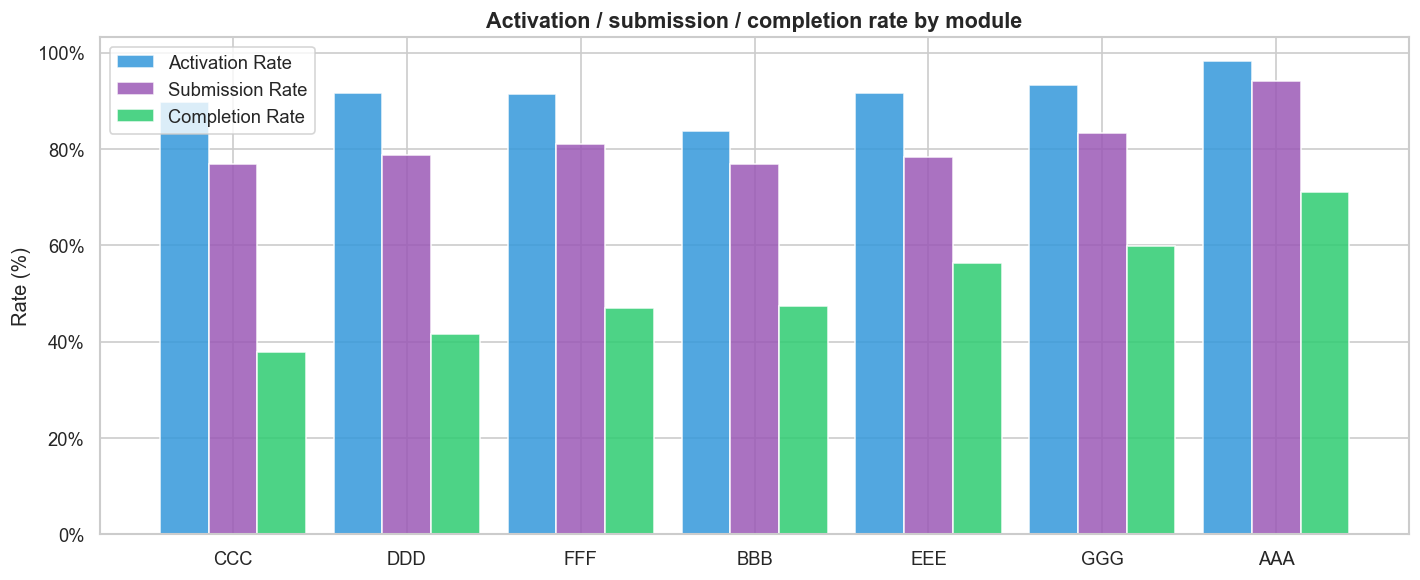

In [4]:
module_funnel = (
    master
    .groupby('code_module')
    .agg(
        registered       = ('id_student', 'count'),
        active           = ('total_clicks', lambda x: (x > 0).sum()),
        submitted_any    = ('submission_count', lambda x: (x > 0).sum()),
        passed           = ('completed', 'sum'),
    )
    .assign(
        activation_rate  = lambda x: x['active']        / x['registered'] * 100,
        submission_rate  = lambda x: x['submitted_any'] / x['registered'] * 100,
        completion_rate  = lambda x: x['passed']        / x['registered'] * 100,
    )
    .reset_index()
    .sort_values('completion_rate', ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(module_funnel))
w = 0.28

ax.bar(x - w, module_funnel['activation_rate'],  w, label='Activation Rate',  color='#3498db', alpha=0.85)
ax.bar(x,     module_funnel['submission_rate'],   w, label='Submission Rate',  color='#9b59b6', alpha=0.85)
ax.bar(x + w, module_funnel['completion_rate'],   w, label='Completion Rate',  color='#2ecc71', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(module_funnel['code_module'])
ax.set_ylabel('Rate (%)')
ax.set_title('Activation / submission / completion rate by module', fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend()
plt.tight_layout()
plt.savefig('../assets/02_module_funnel.png', bbox_inches='tight')
plt.show()

## Cohort retention

Each cohort is one presentation. Weekly activity counts distinct student IDs
across modules. The denominator is that presentation's peak weekly activity in
weeks 0–2. We cap the index at 100% and average presentations equally for the
week-to-week change. Week 0 covers days 0–6 from course start.


In [5]:
student_vle = pd.read_csv(RAW + 'studentVle.csv')

student_vle['week'] = (student_vle['date'] // 7).astype(int)
student_vle = student_vle[student_vle['week'].between(0, 25) & student_vle['sum_click'].gt(0)]

vle_cohort = student_vle.merge(
    master[['id_student','code_module','code_presentation']].drop_duplicates(),
    on=['id_student','code_module','code_presentation'],
    how='inner'
)
print(f'VLE events for cohort analysis: {len(vle_cohort):,}')

VLE events for cohort analysis: 8,065,297


In [6]:
weekly_active = (
    vle_cohort
    .groupby(['code_presentation', 'week'])['id_student']
    .nunique()
    .reset_index(name='active_students')
)

# max over weeks 0-2 so late joiners don't deflate the baseline
baseline = (
    weekly_active[weekly_active['week'] <= 2]
    .groupby('code_presentation')['active_students']
    .max()
    .rename('cohort_size')
)

weekly_active = weekly_active.join(baseline, on='code_presentation')
weekly_active['retention_rate'] = (
    weekly_active['active_students'] / weekly_active['cohort_size']
).clip(upper=1.0)

retention_pivot = (
    weekly_active
    .pivot(index='code_presentation', columns='week', values='retention_rate')
    .fillna(0)
)
print(f'Cohort x week matrix: {retention_pivot.shape}')
weekly_active.to_csv(PROC + 'weekly_retention.csv', index=False)

Cohort x week matrix: (4, 26)


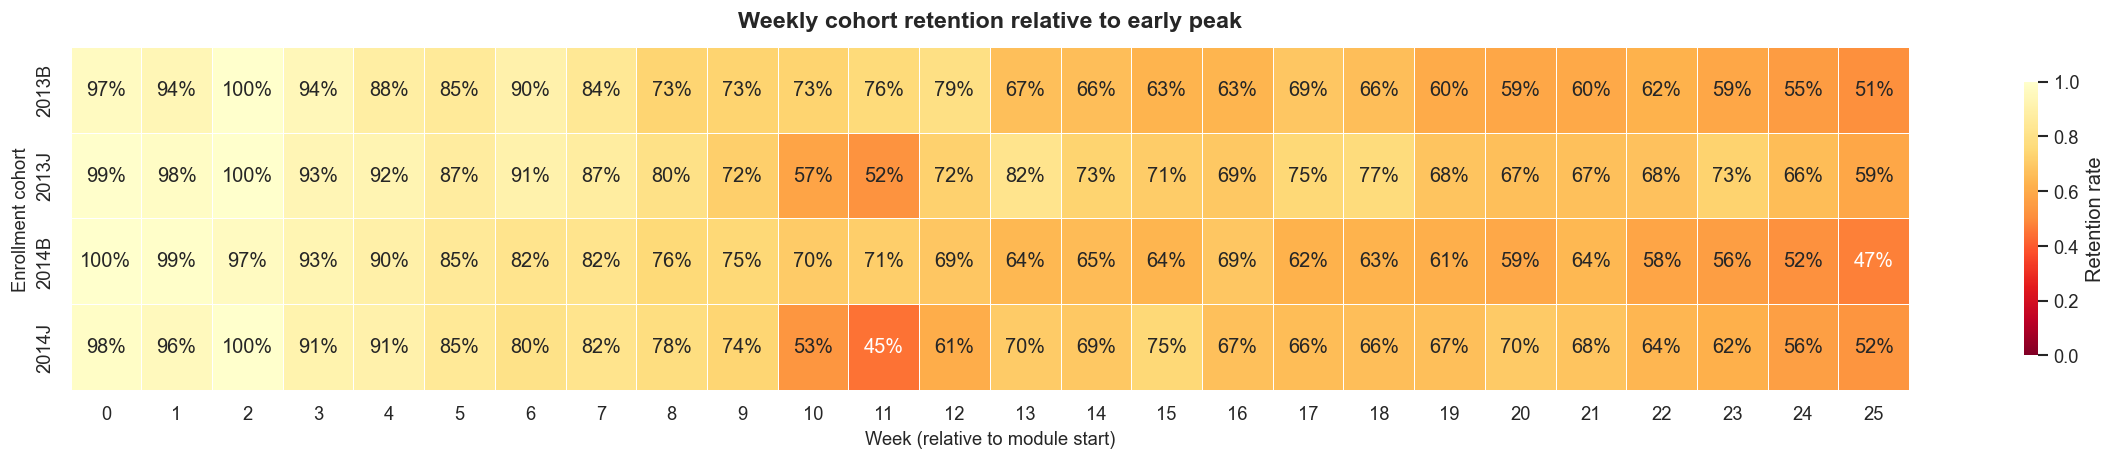


Steepest average retention drop: Week 10 (-10.1 pp on average)


In [7]:
fig, ax = plt.subplots(figsize=(20, 4))

sns.heatmap(
    retention_pivot,
    annot=True, fmt='.0%',
    cmap='YlOrRd_r',
    linewidths=0.4,
    ax=ax, vmin=0, vmax=1,
    cbar_kws={'label': 'Retention rate', 'shrink': 0.8}
)
ax.set_title('Weekly cohort retention relative to early peak',
             fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Week (relative to module start)', fontsize=11)
ax.set_ylabel('Enrollment cohort', fontsize=11)

plt.tight_layout()
plt.savefig('../assets/02_cohort_retention_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()

avg_ret        = retention_pivot.mean()
drop           = avg_ret.diff()
worst_week     = drop.idxmin()
drop_magnitude = abs(drop.min()) * 100

print(f'\nSteepest average retention drop: Week {worst_week} (-{drop_magnitude:.1f} pp on average)')

In [8]:
fig = px.line(
    weekly_active,
    x='week', y='retention_rate',
    color='code_presentation',
    markers=True,
    title='Weekly retention curves by enrollment cohort',
    labels={
        'week':              'Week',
        'retention_rate':    'Retention rate',
        'code_presentation': 'Cohort'
    }
)
fig.update_layout(yaxis_tickformat='.0%', hovermode='x unified', height=430)
fig.show()

## Student lifetime value

```
Estimated LTV = module fee
              + P(complete) × re-enrollment rate × module fee
              + P(complete) × referral rate (completed) × referral value
              + P(incomplete) × referral rate (incomplete) × referral value
```

The £2,500 fee is an illustrative UK Open University price assumption. The
re-enrollment and referral rates and referral value are scenario inputs. OULAD
supplies observed completion by full-course click tier and has no transaction
data. The calculation represents illustrative gross revenue and excludes costs
and discounting. The tier comparison is descriptive.


In [9]:
BASE = {
    'module_fee':          2500,
    'reenroll_rate':       0.45,
    'referral_rate_pass':  0.15,
    'referral_rate_fail':  0.02,
    'referral_value':      300,
}

def ltv_model(completion_prob: float, params: dict) -> dict:
    """Return itemised LTV components and total."""
    base      = params['module_fee']
    reenroll  = completion_prob * params['reenroll_rate']       * params['module_fee']
    referral  = (
        completion_prob       * params['referral_rate_pass'] * params['referral_value'] +
        (1 - completion_prob) * params['referral_rate_fail'] * params['referral_value']
    )
    return {
        'base_revenue':     base,
        'reenroll_revenue': reenroll,
        'referral_revenue': referral,
        'total_ltv':        base + reenroll + referral,
    }

tier_completion = (
    master
    .groupby('engagement_tier', observed=True)['completed']
    .mean()
    .reset_index(name='completion_prob')
)

ltv_rows = []
for _, row in tier_completion.iterrows():
    components = ltv_model(row['completion_prob'], BASE)
    ltv_rows.append({'engagement_tier': row['engagement_tier'],
                     'completion_prob': row['completion_prob'], **components})

ltv_df = pd.DataFrame(ltv_rows)
print('Modeled LTV by engagement tier:')
print(
    ltv_df.assign(
        completion_prob     = ltv_df['completion_prob'].map('{:.1%}'.format),
        base_revenue        = ltv_df['base_revenue'].map('£{:,.0f}'.format),
        reenroll_revenue    = ltv_df['reenroll_revenue'].map('£{:,.0f}'.format),
        referral_revenue    = ltv_df['referral_revenue'].map('£{:,.0f}'.format),
        total_ltv           = ltv_df['total_ltv'].map('£{:,.0f}'.format),
    ).to_string(index=False)
)

Modeled LTV by engagement tier:
engagement_tier completion_prob base_revenue reenroll_revenue referral_revenue total_ltv
           High           88.6%       £2,500             £996              £41    £3,537
       Inactive            0.1%       £2,500               £1               £6    £2,507
            Low           19.5%       £2,500             £220              £14    £2,733
         Medium           65.8%       £2,500             £741              £32    £3,272


In [10]:
tier_order = ['Inactive', 'Low', 'Medium', 'High']
ltv_plot = ltv_df.set_index('engagement_tier').reindex(tier_order)

fig = go.Figure()
components = [
    ('base_revenue',     'Module fee',        '#2c3e50'),
    ('reenroll_revenue', 'Re-enroll revenue', '#2980b9'),
    ('referral_revenue', 'Referral revenue',  '#27ae60'),
]
for col, label, color in components:
    fig.add_trace(go.Bar(
        name=label,
        x=ltv_plot.index.tolist(),
        y=ltv_plot[col].values,
        marker_color=color
    ))

fig.update_layout(
    barmode='stack',
    title='Student LTV by engagement tier — breakdown by revenue component',
    xaxis_title='Engagement tier',
    yaxis_title='Estimated LTV (£)',
    yaxis_tickprefix='£', yaxis_tickformat=',',
    height=430
)
fig.show()

ltv_gap = ltv_plot.loc['High','total_ltv'] - ltv_plot.loc['Inactive','total_ltv']
print(f'\nModeled LTV gap High vs Inactive: £{ltv_gap:,.0f}')


Modeled LTV gap High vs Inactive: £1,030


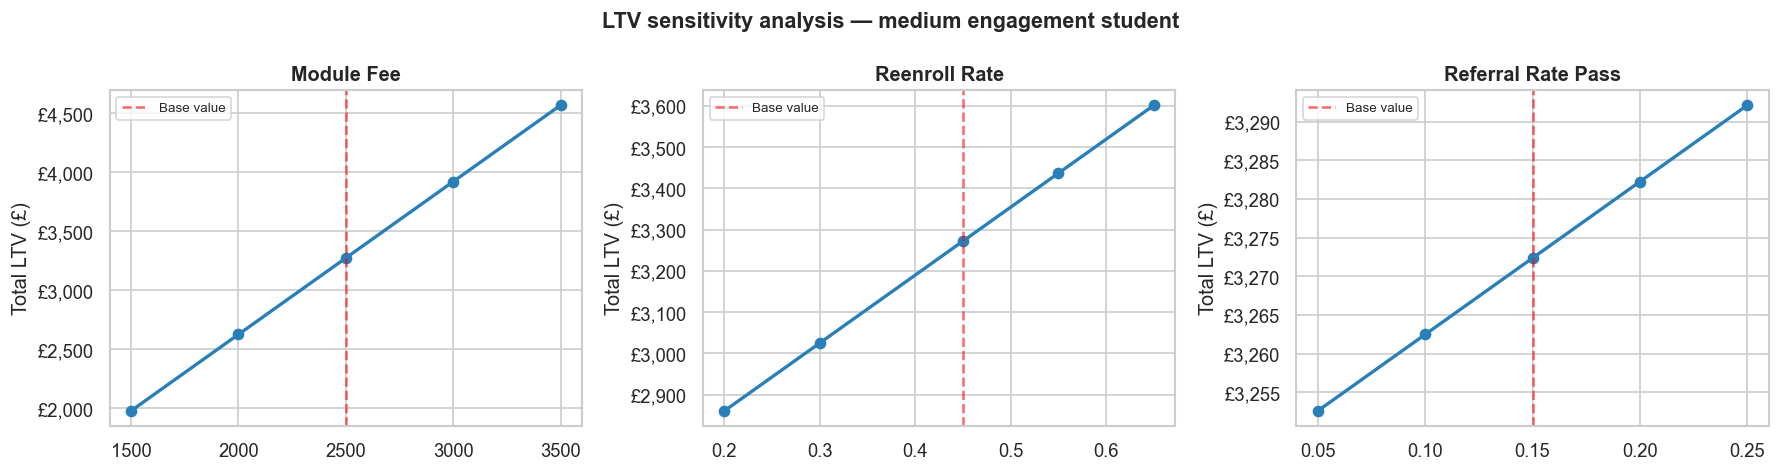

In [11]:
sensitivity_params = [
    ('module_fee',         [1500, 2000, 2500, 3000, 3500]),
    ('reenroll_rate',      [0.20, 0.30, 0.45, 0.55, 0.65]),
    ('referral_rate_pass', [0.05, 0.10, 0.15, 0.20, 0.25]),
]

medium_prob = ltv_df.loc[ltv_df['engagement_tier'] == 'Medium', 'completion_prob'].values[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (param, values) in zip(axes, sensitivity_params):
    ltvs = []
    for v in values:
        params = {**BASE, param: v}
        ltvs.append(ltv_model(medium_prob, params)['total_ltv'])

    ax.plot(values, ltvs, marker='o', linewidth=2, color='#2980b9')
    ax.axvline(BASE[param], color='red', linestyle='--', alpha=0.6, label='Base value')
    ax.set_title(param.replace('_', ' ').title(), fontweight='bold')
    ax.set_ylabel('Total LTV (£)')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'£{x:,.0f}'))
    ax.legend(fontsize=8)

plt.suptitle('LTV sensitivity analysis — medium engagement student', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../assets/02_ltv_sensitivity.png', bbox_inches='tight')
plt.show()

In [12]:
ltv_by_segment = (
    master
    .groupby(['highest_education', 'engagement_tier'], observed=True)['completed']
    .mean()
    .reset_index(name='completion_prob')
)
ltv_by_segment['total_ltv'] = ltv_by_segment['completion_prob'].apply(
    lambda p: ltv_model(p, BASE)['total_ltv']
)

fig = px.bar(
    ltv_by_segment,
    x='highest_education', y='total_ltv',
    color='engagement_tier',
    barmode='group',
    color_discrete_map=TIER_COLORS,
    title='Estimated LTV by prior education and engagement tier',
    labels={
        'total_ltv':          'LTV (£)',
        'highest_education':  'Prior education',
        'engagement_tier':    'Tier'
    }
)
fig.update_layout(yaxis_tickprefix='£', yaxis_tickformat=',', height=430)
fig.show()
